# AuditScribe experiment

Word-level autoregressive generation of smart-contract audit prose with Simple RNN, Bidirectional RNN, LSTM and GRU.

The experiment compares identical dataset splits and optimization rules across architectures. Detailed preprocessing and evaluation definitions are in `docs/methodology.md`. This notebook displays the recorded experiment outputs and supports optional regeneration.

## Reproduce the experiment

Core dependencies are in `requirements.txt`. From the repository root:

```bash
python -m auditscribe.data --download
python -m auditscribe.train
python -m auditscribe.analyze
python -m auditscribe.report
```

The optional cell below runs these steps when `RUN_EXPERIMENT` is enabled. The default displays the included results.

In [1]:
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    import subprocess, sys
    for module, args in [("data", ["--download"]), ("train", []), ("analyze", []), ("report", [])]:
        subprocess.run([sys.executable, "-m", "auditscribe." + module, *args], check=True)


## Dataset characteristics and experimental configuration

In [2]:
import json
from pathlib import Path
summary = json.loads(Path("results/dataset_summary.json").read_text())
config = json.loads(Path("results/config.json").read_text())
print(json.dumps(summary, indent=2))
print(json.dumps(config, indent=2))

{
  "source": "https://github.com/solodit/solodit_content",
  "revision": "4d5330d12978c7a8fc2aab5b171112784fb671bd",
  "seed": 42,
  "context": 24,
  "stride": 3,
  "vocabulary_size": 4000,
  "reports": 483,
  "passages": 5140,
  "splits": {
    "train": {
      "reports": 387,
      "protocol_groups": 294,
      "tokens": 501620,
      "unknown_fraction": 0.03472150233244289,
      "available_windows": 136015,
      "used_windows": 136015
    },
    "validation": {
      "reports": 48,
      "protocol_groups": 37,
      "tokens": 76859,
      "unknown_fraction": 0.057833175034803994,
      "available_windows": 20660,
      "used_windows": 10000
    },
    "test": {
      "reports": 48,
      "protocol_groups": 37,
      "tokens": 51873,
      "unknown_fraction": 0.05791066643533244,
      "available_windows": 14026,
      "used_windows": 10000
    }
  }
}
{
  "epochs": 16,
  "seed": 42,
  "batch_size": 512,
  "embedding": 64,
  "hidden": 96,
  "dropout": 0.25,
  "optimizer": "AdamW",

## Model implementation

All models use embeddings of width 64, hidden width 96 per direction, one recurrent layer and dropout 0.25. Bidirectional RNN operates only over the known past context; the next token remains outside its input. Model definitions are shown below.

In [3]:
print(Path("auditscribe/model.py").read_text())

import torch
from torch import nn

class LanguageModel(nn.Module):
    def __init__(self, kind, vocab_size, embedding=64, hidden=96):
        super().__init__()
        if kind not in ['rnn','birnn','lstm','gru']: raise ValueError(kind)
        self.kind=kind
        self.embedding=nn.Embedding(vocab_size,embedding)
        cls={'rnn':nn.RNN,'birnn':nn.RNN,'lstm':nn.LSTM,'gru':nn.GRU}[kind]
        self.recurrent=cls(embedding,hidden,batch_first=True,bidirectional=kind=='birnn')
        self.dropout=nn.Dropout(.25)
        self.output=nn.Linear(hidden*(2 if kind=='birnn' else 1),vocab_size)
    def forward(self,x):
        _,state=self.recurrent(self.embedding(x))
        h=state[0] if isinstance(state,tuple) else state
        # Both directions encode ONLY the supplied past window, never target tokens.
        features=torch.cat((h[-2],h[-1]),dim=-1) if self.kind=='birnn' else h[-1]
        return self.output(self.dropout(features))



## Quantitative model comparison

In [4]:
metrics = json.loads(Path("results/metrics.json").read_text())
print(f"{'Model':<8} {'Loss':>8} {'Perplexity':>12} {'Accuracy':>10} {'Word acc.':>10} {'Seconds':>10}")
for r in metrics:
    print(f"{r['model'].upper():<8} {r['loss']:>8.4f} {r['perplexity']:>12.2f} {r['accuracy']:>10.2%} {r['word_accuracy']:>10.2%} {r['training_seconds']:>10.1f}")
print("\nUnigram baseline:", json.loads(Path("results/baseline.json").read_text()))

Model        Loss   Perplexity   Accuracy  Word acc.    Seconds
RNN        4.7873       119.97     19.89%     17.87%      142.7
BIRNN      4.8832       132.06     18.90%     16.57%      245.2
LSTM       4.7365       114.03     20.43%     18.20%      267.1
GRU        4.7279       113.06     20.74%     18.32%      254.4

Unigram baseline: {'model': 'smoothed unigram', 'loss': 5.855612774219154, 'perplexity': 349.18880840793935, 'accuracy': 0.0718}


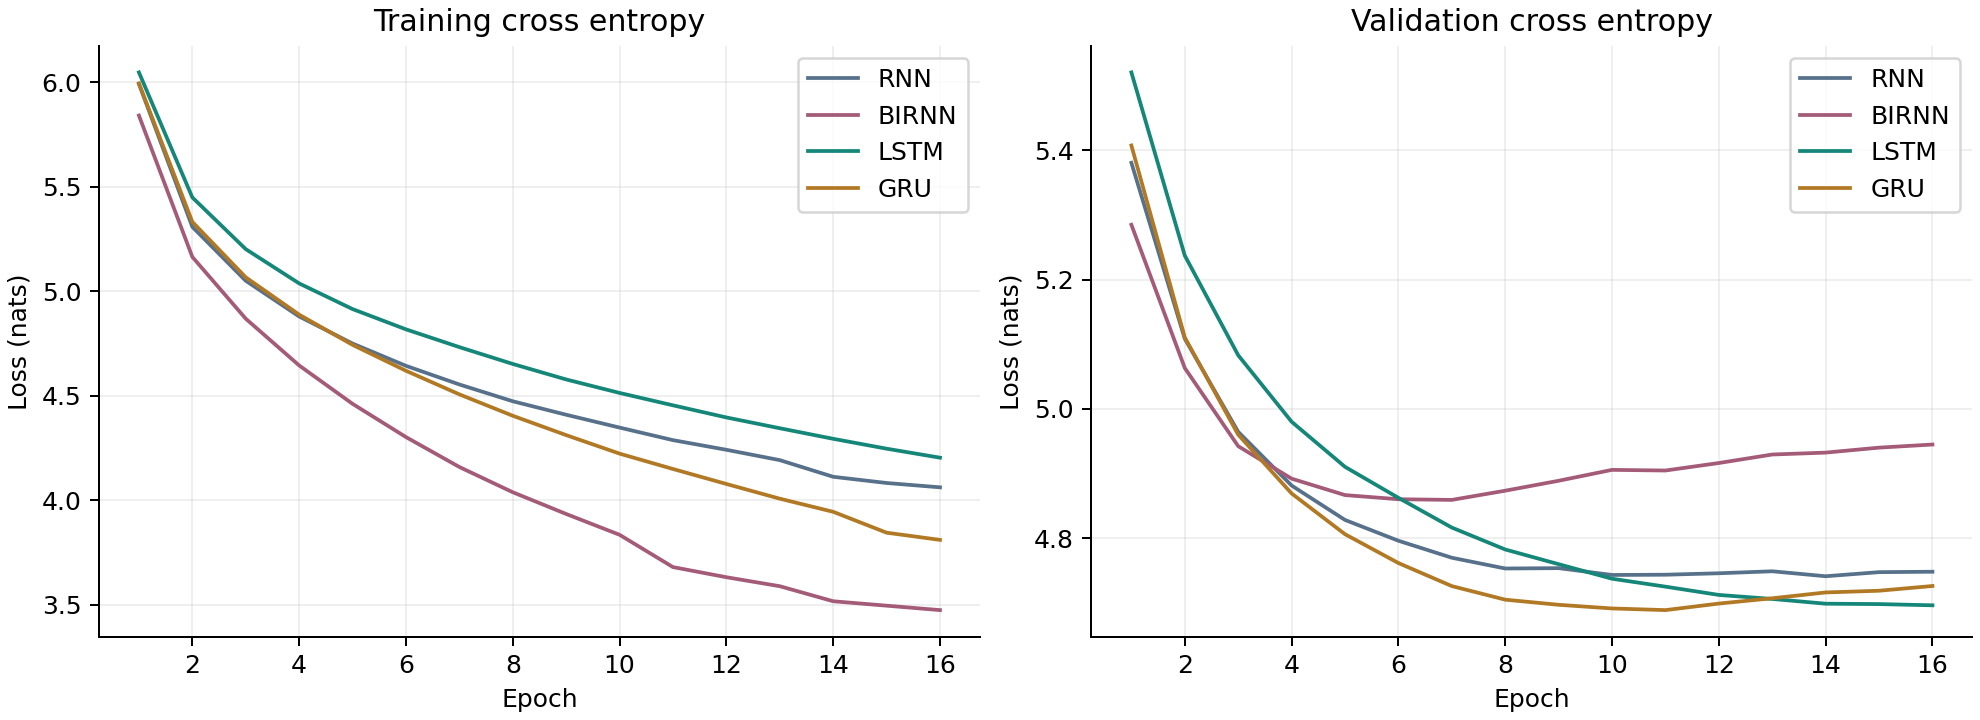

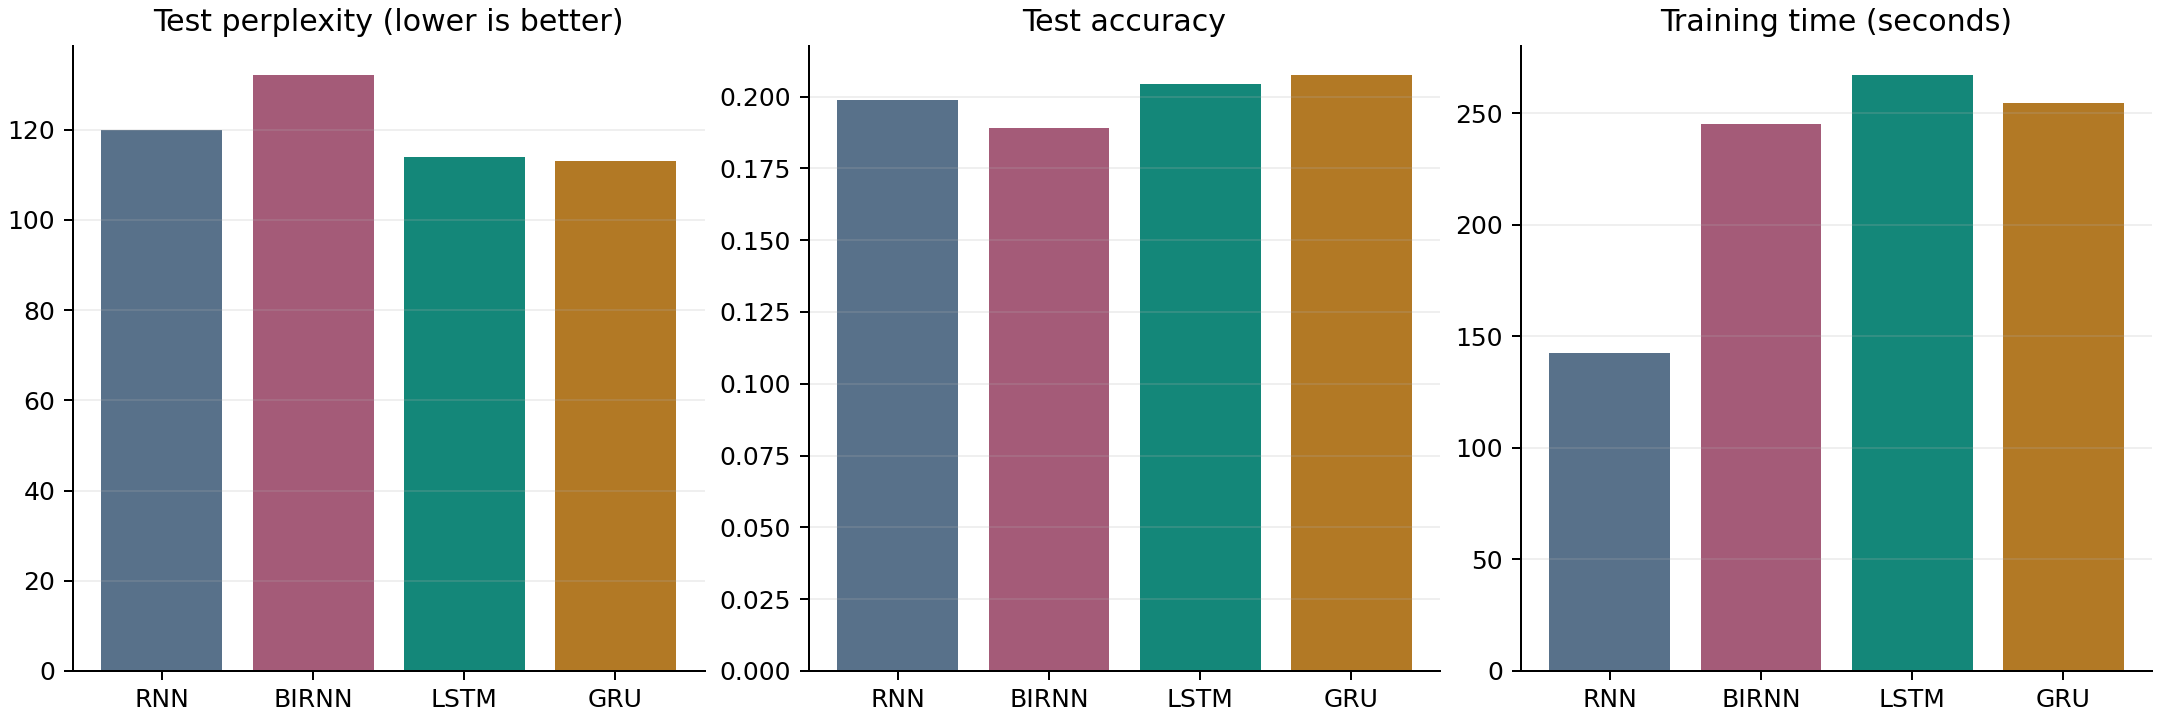

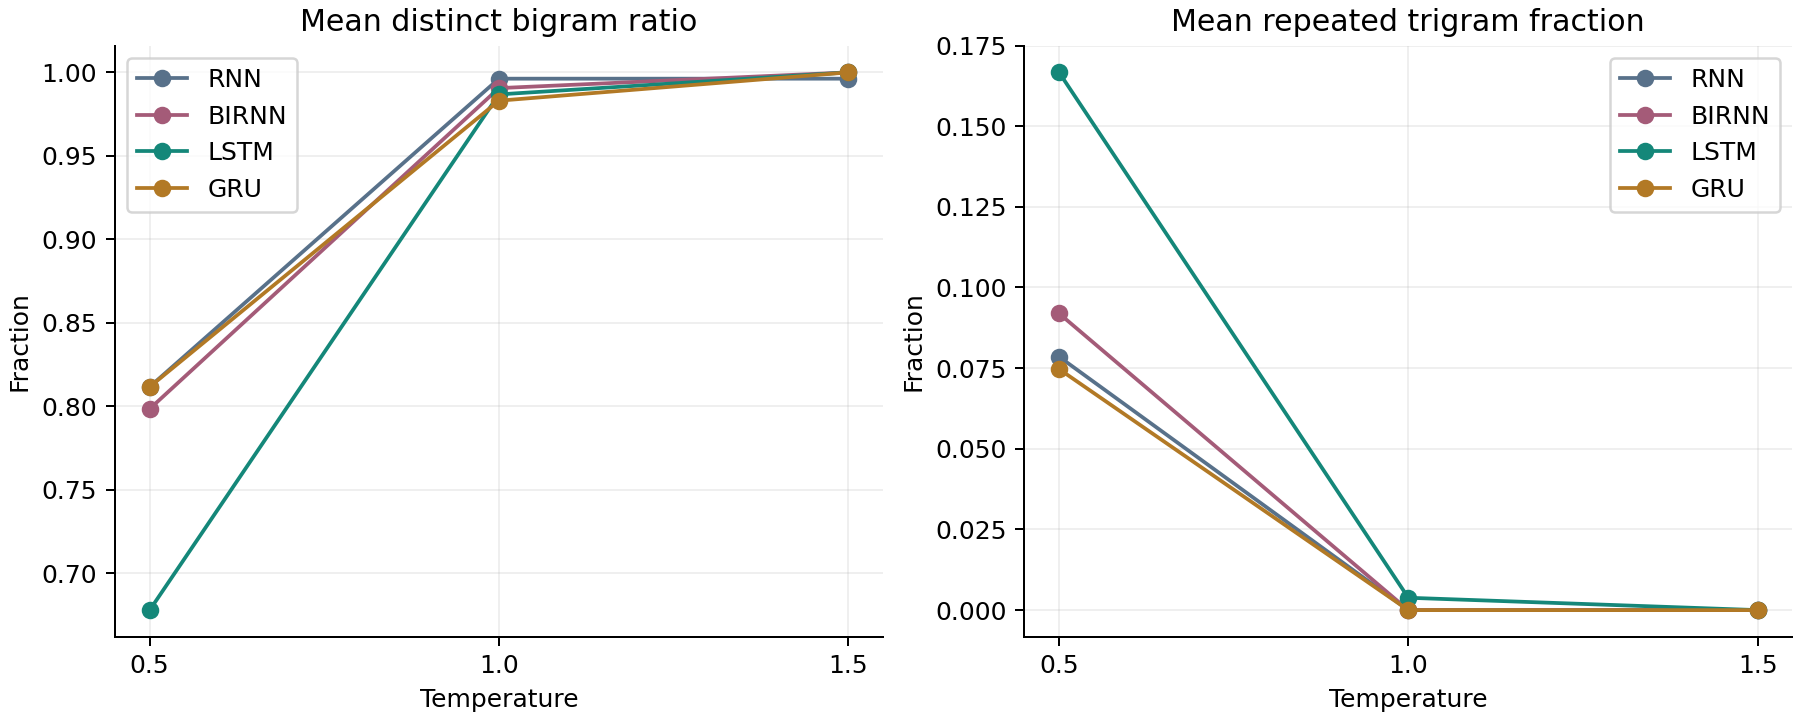

In [5]:
from IPython.display import Image, display
for name in ["learning_curves", "model_comparison", "temperature_analysis"]:
    display(Image(filename=f"results/{name}.png"))

## Generated text at three temperatures

The same prompt and generation seed are shown for all four models at temperatures 0.5, 1.0 and 1.5. Each continuation contains 60 generated tokens. The complete set of 108 outputs is available in `results/generated_samples.txt`.

In [6]:
samples = json.loads(Path("results/samples.json").read_text())
for s in samples:
    if s["prompt"] == "the contract does not validate" and s["seed"] == 101:
        print(f"\n{s['model'].upper()} | T={s['temperature']} | seed={s['seed']}")
        print("Prompt:", s["prompt"])
        print("Continuation:", s["text"])


RNN | T=0.5 | seed=101
Prompt: the contract does not validate
Continuation: the owner is not checked in the contract . the identifier function can be used by the owner is not and if it s identifier is not set to the identifier function . this can lead to the following test to ensure that the identifier is not called , as it requires an empty service . the contract attempts to

RNN | T=1.0 | seed=101
Prompt: the contract does not validate
Continuation: that property is used to in other information when such the recipient . user created should be used with additional try to pull reverts of the yield . consider adding the check to add a malicious reward rate to send the conditions is a valid operation . an attacker can abuse all an deposit service . a contract attempts to

RNN | T=1.5 | seed=101
Prompt: the contract does not validate
Continuation: those property epoch iterates to in other information scenario worth chainlink recipient . user price limits that limiting is dependent and un

## Coherence diversity contextual consistency and repetition

In [7]:
from IPython.display import Markdown
print(Path("results/temperature_summary.csv").read_text())
display(Markdown(Path("docs/qualitative_analysis.md").read_text()))

model,temperature,n,distinct_1,distinct_2,repetition_3
rnn,0.5,9,0.5166666666666667,0.8116760828625236,0.078544061302682
rnn,1.0,9,0.7907407407407407,0.9962335216572504,0.0
rnn,1.5,9,0.9074074074074073,0.9962335216572504,0.0
birnn,0.5,9,0.5037037037037037,0.7984934086629002,0.09195402298850575
birnn,1.0,9,0.7611111111111111,0.9905838041431261,0.0
birnn,1.5,9,0.9037037037037037,1.0,0.0
lstm,0.5,9,0.40185185185185185,0.6779661016949152,0.16666666666666666
lstm,1.0,9,0.7703703703703704,0.9868173258003766,0.0038314176245210804
lstm,1.5,9,0.8925925925925926,1.0,0.0
gru,0.5,9,0.5018518518518519,0.8116760828625236,0.07471264367816094
gru,1.0,9,0.7537037037037037,0.983050847457627,0.0
gru,1.5,9,0.9166666666666666,1.0,0.0



# Qualitative analysis of generated audit text

The comparison below inspects the fixed prompt `the contract does not validate`, generation seed 101 and all three temperatures for every model. These are descriptive observations, not blinded human ratings. Complete continuations for this comparison and all other prompts/seeds are retained in `results/generated_samples.txt` and `results/generated_samples.md`.

## Coherence and contextual consistency

| Model | Temperature 0.5 | Temperature 1.0 | Temperature 1.5 |
|---|---|---|---|
| Simple RNN | Starts with a relevant owner-check statement, then repeats identifier/function phrases and ends unfinished. | Moves from a recipient to yield and rewards; local security vocabulary lacks a consistent explanation. | Rare terms and broken syntax dominate; the original validation context is lost. |
| Bidirectional RNN | Includes recommendation phrasing, but the owner, loop, balance and constructor are not connected logically. | Shifts between recipients, borrowing and maintenance with grammatical errors. | Fragmented mentions of transfers, prices and other concepts have weak contextual consistency. |
| LSTM | Produces repeated grammatical fragments around `identifier function can be used`; repetition overwhelms meaning. | Contains recognizable audit phrases but drifts between yield, reward information and validation. | Greater word variety comes with incoherent combinations and unstable sentence structure. |
| GRU | Retains owner/address/contract vocabulary, but repeats generic statements and the phrase `as low as low`. | Mentions governance, signatures and migration without explaining a single vulnerability. | Broad vocabulary and low repetition do not produce a coherent causal account. |

At temperature 0.5, the Simple RNN continuation begins `the owner is not checked in the contract`. This is locally compatible with the prompt, but the remainder does not sustain a clear finding. The GRU continuation stays broadly within the access-control domain while repeating generic contract/address language. LSTM is the most repetitive of the four at this temperature according to the mean repeated-trigram measurement (0.167).

## Diversity and repetition

Higher temperatures flatten the token distribution and generally increase lexical diversity. At 0.5, mean distinct-bigram ratios range from 0.678 to 0.812 and repeated-trigram fractions from 0.075 to 0.167. At 1.0, distinct-bigram ratios rise to 0.983-0.996; repeated-trigram fractions are zero except for LSTM (0.0038). At 1.5, mean distinct-bigram ratios are at least 0.996 and repeated-trigram fractions are zero for every model.

These statistics measure repetition within individual 60-token continuations. A zero repeated-trigram fraction does not establish fluent or accurate prose. The examples at 1.5 demonstrate this distinction: they contain diverse vocabulary but frequently lose grammar and topic continuity.

## Temperature choice and model selection

Temperature 0.5 is the most defensible setting among those tested for short, recognizable audit-style fragments, although repetition remains substantial. Temperature 1.0 exposes the trade-off between variety and consistency. Temperature 1.5 is unsuitable for readable audit text in this experiment. No temperature yields reliably correct technical findings.

GRU is selected overall because it has the lowest validation loss, lowest test loss/perplexity and highest primary test accuracy. It also has the lowest mean repeated-trigram fraction at temperature 0.5 and ties Simple RNN for the highest distinct-bigram ratio at that temperature. It uses fewer parameters and less measured training time than LSTM in this run. The numerical gap between GRU and LSTM is small, and qualitative inspection does not establish decisive semantic superiority. The conclusion is limited to this corpus, configuration and training seed.

## Limitations

All four models can generate misleading or technically false statements. The experiment evaluates language modelling, not vulnerability detection or remediation correctness. Code identifiers and numbers were simplified during preprocessing; this limits technical specificity. Short seed contexts, a bounded vocabulary and one training seed also restrict conclusions. The protocol grouping is heuristic and does not eliminate all possible semantic overlap between related audits.


## Conclusion

In [8]:
best = min(metrics, key=lambda r: r["best_validation_loss"])
print(f"Selected model: {best['model'].upper()}")
print(f"Test accuracy: {best['accuracy']:.2%}; perplexity: {best['perplexity']:.2f}")
print("Selection uses validation loss. Conclusions are limited to this corpus, configuration and training seed.")

Selected model: GRU
Test accuracy: 20.74%; perplexity: 113.06
Selection uses validation loss. Conclusions are limited to this corpus, configuration and training seed.
